# Big Data Platforms

## PySpark - Exploratory Data Analysis (EDA)  

### Chicago Food Inspection 

This notebook demonstrates the use of PySpark dataframe APIs and Spark SQL

**Dataset:**
https://www.kaggle.com/chicago/chi-restaurant-inspections

Author [Ashish Pujari](apujari@uchicago.edu)

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
from pyspark.sql import SparkSession

spark = SparkSession.builder.appName("ChicagoFoodInspection").getOrCreate()

# Display Spark configuration settings
spark.sparkContext.getConf().getAll()

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/16 16:26:13 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


[('spark.driver.port', '42885'),
 ('spark.driver.host', 'jkanellopoulos-1.c.adsp-31011-ip07-f26.internal'),
 ('spark.rdd.compress', 'True'),
 ('spark.hadoop.fs.s3a.vectored.read.min.seek.size', '128K'),
 ('spark.app.startTime', '1794846373659'),
 ('spark.executor.extraJavaOptions',
  '-Djava.net.preferIPv6Addresses=false -XX:+IgnoreUnrecognizedVMOptions --add-modules=jdk.incubator.vector --add-opens=java.base/java.lang=ALL-UNNAMED --add-opens=java.base/java.lang.invoke=ALL-UNNAMED --add-opens=java.base/java.lang.reflect=ALL-UNNAMED --add-opens=java.base/java.io=ALL-UNNAMED --add-opens=java.base/java.net=ALL-UNNAMED --add-opens=java.base/java.nio=ALL-UNNAMED --add-opens=java.base/java.util=ALL-UNNAMED --add-opens=java.base/java.util.concurrent=ALL-UNNAMED --add-opens=java.base/java.util.concurrent.atomic=ALL-UNNAMED --add-opens=java.base/jdk.internal.ref=ALL-UNNAMED --add-opens=java.base/sun.nio.ch=ALL-UNNAMED --add-opens=java.base/sun.nio.cs=ALL-UNNAMED --add-opens=java.base/sun.securi

In [3]:
spark

### Load Data

In [4]:
# Download CSV from GCS
# Workaround only; not recommended for very large datasets

from google.cloud import storage

client = storage.Client()

bucket = client.bucket("adsp-31011-ip07-f26-bucket")
blob = bucket.blob("chicago-food-inspections/food-inspections.csv")

blob.download_to_filename("/tmp/food-inspections.csv")

In [5]:
df = spark.read.csv(
    "file:///tmp/food-inspections.csv",
    header=True,
    inferSchema=True
)

In [6]:
df.printSchema()

root
 |-- Inspection ID: integer (nullable = true)
 |-- DBA Name: string (nullable = true)
 |-- AKA Name: string (nullable = true)
 |-- License #: integer (nullable = true)
 |-- Facility Type: string (nullable = true)
 |-- Risk: string (nullable = true)
 |-- Address: string (nullable = true)
 |-- City: string (nullable = true)
 |-- State: string (nullable = true)
 |-- Zip: integer (nullable = true)
 |-- Inspection Date: timestamp (nullable = true)
 |-- Inspection Type: string (nullable = true)
 |-- Results: string (nullable = true)
 |-- Violations: string (nullable = true)
 |-- Latitude: double (nullable = true)
 |-- Longitude: double (nullable = true)
 |-- Location: string (nullable = true)



In [7]:
#it is good when the data types are as expected. this indicates no corrupted records
df.dtypes

[('Inspection ID', 'int'),
 ('DBA Name', 'string'),
 ('AKA Name', 'string'),
 ('License #', 'int'),
 ('Facility Type', 'string'),
 ('Risk', 'string'),
 ('Address', 'string'),
 ('City', 'string'),
 ('State', 'string'),
 ('Zip', 'int'),
 ('Inspection Date', 'timestamp'),
 ('Inspection Type', 'string'),
 ('Results', 'string'),
 ('Violations', 'string'),
 ('Latitude', 'double'),
 ('Longitude', 'double'),
 ('Location', 'string')]

### Partioning

Apache Spark can run a single concurrent task for every partition of an RDD, up to the total number of cores in the cluster.The number of partitions in spark should be decided thoughtfully based on the cluster configuration and requirements of the application. Having too large a number of partitions or too few - is not an ideal solution. 

Data can be repartitioned using the PySpark <code>repartition()</code> method randomly by increasing or decreasing the number of partitions, or repartitioned by selected columns.

Note: When you want to reduce the number of partitions, it is recommended to use PySpark <code>coalesce()</code> 
over <code>repartition()</code> as it uses fewer resources due to less number of shuffles it takes.

In [8]:
#display number of records by partition
def displaypartitions(df):
    #number of records by partition
    num = df.rdd.getNumPartitions()
    print("Partitions:", num)
    df.withColumn("partitionId", F.spark_partition_id())\
        .groupBy("partitionId")\
        .count()\
        .orderBy(F.asc("count"))\
        .show(num)

In [9]:
#number of partitions
df.rdd.getNumPartitions()

8

In [10]:
displaypartitions(df)

Partitions: 8


[Stage 2:>                                                          (0 + 8) / 8]

+-----------+-----+
|partitionId|count|
+-----------+-----+
|          7|16454|
|          6|19027|
|          0|21838|
|          5|23619|
|          2|23698|
|          3|23797|
|          1|24018|
|          4|25638|
+-----------+-----+



In [11]:
#re-partition the data
df = df.repartition(32)
displaypartitions(df)

[Stage 5:======================>                                    (3 + 5) / 8]

Partitions: 32
+-----------+-----+
|partitionId|count|
+-----------+-----+
|         22| 5564|
|         23| 5564|
|         26| 5564|
|         27| 5564|
|         28| 5564|
|         29| 5564|
|          1| 5565|
|          2| 5565|
|          3| 5565|
|          4| 5565|
|          5| 5565|
|          6| 5565|
|          7| 5565|
|         13| 5565|
|         17| 5565|
|         18| 5565|
|         20| 5565|
|         21| 5565|
|         24| 5565|
|         25| 5565|
|         30| 5565|
|          0| 5566|
|         12| 5566|
|         14| 5566|
|         15| 5566|
|         16| 5566|
|         19| 5566|
|         31| 5566|
|          8| 5567|
|          9| 5567|
|         10| 5567|
|         11| 5567|
+-----------+-----+



In [12]:
df = df.coalesce(10)
displaypartitions(df)

[Stage 12:===========================================>              (6 + 2) / 8]

Partitions: 10
+-----------+-----+
|partitionId|count|
+-----------+-----+
|          8|16694|
|          9|16694|
|          3|16695|
|          5|16695|
|          2|16697|
|          4|16697|
|          6|16697|
|          7|16698|
|          0|22261|
|          1|22261|
+-----------+-----+



In [13]:
#repartition based on one or more columns
df = df.repartition(F.col("Zip"))
displaypartitions(df)

[Stage 19:==================================================>       (7 + 1) / 8]

Partitions: 9
+-----------+------+
|partitionId| count|
+-----------+------+
|          0|178089|
+-----------+------+



In [14]:
df = df.repartition(F.col("Results"),F.col("Zip"))
displaypartitions(df)

[Stage 26:==================================================>       (7 + 1) / 8]

Partitions: 9
+-----------+------+
|partitionId| count|
+-----------+------+
|          0|178089|
+-----------+------+



### Summarize

In [15]:
df.describe().show()
#df.summary().show()

26/11/16 16:26:34 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
[Stage 35:=============================================>            (7 + 2) / 9]

+-------+-----------------+--------------------+--------------------+-----------------+-------------------+------------+-------------------+----------+------+-----------------+--------------------+--------------------+--------------------+-------------------+--------------------+--------------------+
|summary|    Inspection ID|            DBA Name|            AKA Name|        License #|      Facility Type|        Risk|            Address|      City| State|              Zip|     Inspection Type|             Results|          Violations|           Latitude|           Longitude|            Location|
+-------+-----------------+--------------------+--------------------+-----------------+-------------------+------------+-------------------+----------+------+-----------------+--------------------+--------------------+--------------------+-------------------+--------------------+--------------------+
|  count|           178089|              178089|              175653|           178073|       

In [16]:
#display top 2 rows as RDD
df.head(2)

[Row(Inspection ID=2240246, DBA Name='NEW HONG KONG BUFFET, INC', AKA Name='NEW HONG KONG BUFFET', License #=2510903, Facility Type='Restaurant', Risk='Risk 1 (High)', Address='6249 N MCCORMICK RD ', City='CHICAGO', State='IL', Zip=60659, Inspection Date=datetime.datetime(2018, 11, 15, 0, 0), Inspection Type='Short Form Complaint', Results='Fail', Violations='10. ADEQUATE HANDWASHING SINKS PROPERLY SUPPLIED AND ACCESSIBLE - Comments: HAND WASHING SINK LOCATED IN THE BUFFET SERVING AREA NOT ACCESSIBLE. FOUND BLOCKED FOR USE BY METAL PLATE CART, PLATE INSIDE SINK. INSTRUCTED THE SINK MUST BE ACCESSIBLE AT ALL TIMES. MANAGER REMOVED ALL. PRIORITY FOUNDATION VIOLATION. 7-38-030(C) CITATION ISSUED. | 10. ADEQUATE HANDWASHING SINKS PROPERLY SUPPLIED AND ACCESSIBLE - Comments: NO PAPER TOWELS LOCATED AT THE BUFFET HAND WASHING SINK. MUST PROVIDE AT ALL TIMES. MANAGER PROVIDED. PRIORITY FOUNDATION VIOLATION. NO CITATION ISSUED. SEE VIOLATION #10 ABOVE 5-205.11. | 15. FOOD SEPARATED AND PROTECT

In [17]:
df.count()

178089

In [18]:
#display top 2 rows - preferred
df.show(2)

[Stage 48:=====================>                                    (3 + 5) / 8]

+-------------+--------------------+--------------------+---------+-------------+-------------+--------------------+-------+-----+-----+-------------------+--------------------+-------+--------------------+------------------+------------------+--------------------+
|Inspection ID|            DBA Name|            AKA Name|License #|Facility Type|         Risk|             Address|   City|State|  Zip|    Inspection Date|     Inspection Type|Results|          Violations|          Latitude|         Longitude|            Location|
+-------------+--------------------+--------------------+---------+-------------+-------------+--------------------+-------+-----+-----+-------------------+--------------------+-------+--------------------+------------------+------------------+--------------------+
|      2240246|NEW HONG KONG BUF...|NEW HONG KONG BUFFET|  2510903|   Restaurant|Risk 1 (High)|6249 N MCCORMICK RD |CHICAGO|   IL|60659|2018-11-15 00:00:00|Short Form Complaint|   Fail|10. ADEQUATE HAND

In [19]:
#truncate = False displays all the row contents in the output
df.show(2,truncate=False)

+-------------+------------------------------+--------------------------+---------+-------------+-------------+--------------------+-------+-----+-----+-------------------+---------------------+-------+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

### Select Columns

In [20]:
#Show single column
df.select("DBA Name").show(5)

+--------------------+
|            DBA Name|
+--------------------+
|NEW HONG KONG BUF...|
|MS. B'S KITCHEN &...|
|         KABAB GRILL|
|MS. B'S KITCHEN &...|
|CREMERIA SANTA MA...|
+--------------------+
only showing top 5 rows


In [21]:
#Show more than one column
df.select("DBA Name", "Address").show(5)

+--------------------+--------------------+
|            DBA Name|             Address|
+--------------------+--------------------+
|NEW HONG KONG BUF...|6249 N MCCORMICK RD |
|MS. B'S KITCHEN &...|   4203 W CERMAK RD |
|         KABAB GRILL|3220-3222 W BRYN ...|
|MS. B'S KITCHEN &...|   4203 W CERMAK RD |
|CREMERIA SANTA MA...|     3424 W 26TH ST |
+--------------------+--------------------+
only showing top 5 rows


In [22]:
#List of distinct Results
df.select('Results').distinct().show()

+--------------------+
|             Results|
+--------------------+
|           Not Ready|
|                Fail|
|            No Entry|
|Business Not Located|
|  Pass w/ Conditions|
|     Out of Business|
|                Pass|
+--------------------+



In [23]:
#count the number of distinct Results
df.select('Results').distinct().count()

7

In [24]:
#Count of distinct Facility Types
df.select('Facility Type').distinct().count()

464

When the requested error on the result is high (> 1%), approximate distinct counting is very fast and returns results for a fraction of the cost of computing the exact result. In fact, the performance is more or less the same for a target error of 20% or 1%.

In [25]:
#Approximate Count of distinct facilities
from pyspark.sql.functions import approxCountDistinct

df.select(approxCountDistinct("Facility Type", rsd = 0.01)).show()

/opt/conda/lib/python3.10/site-packages/pyspark/sql/functions/builtin.py:6547: FutureWarning: Deprecated in 2.1, use approx_count_distinct instead.
  warnings.warn("Deprecated in 2.1, use approx_count_distinct instead.", FutureWarning)
[Stage 88:>                                                         (0 + 1) / 1]

+------------------------------------+
|approx_count_distinct(Facility Type)|
+------------------------------------+
|                                 460|
+------------------------------------+



### Missing values

In [26]:
#Find the number of missing values for each column
from pyspark.sql.functions import isnan, when, count, col
df.select([count(when(df[c].isNull(), c)).alias(c) for c in df.columns]).show()

[Stage 92:===========================================>              (6 + 2) / 8]

+-------------+--------+--------+---------+-------------+----+-------+----+-----+---+---------------+---------------+-------+----------+--------+---------+--------+
|Inspection ID|DBA Name|AKA Name|License #|Facility Type|Risk|Address|City|State|Zip|Inspection Date|Inspection Type|Results|Violations|Latitude|Longitude|Location|
+-------------+--------+--------+---------+-------------+----+-------+----+-----+---+---------------+---------------+-------+----------+--------+---------+--------+
|            0|       0|    2436|       16|         4709|  69|      0| 156|   32| 76|              0|              1|      0|     47695|     664|      664|     664|
+-------------+--------+--------+---------+-------------+----+-------+----+-----+---+---------------+---------------+-------+----------+--------+---------+--------+



In [27]:
df.count()

178089

In [28]:
#Count inspections with no missing values in the row
df.dropna().count()

128594

In [29]:
#Count inspections with no missing Facility type - Method 1
df.dropna(thresh=1,subset=('Facility Type')).count()

173380

In [30]:
#Count inspections with no missing Facility type - Method 2
df.select("Facility Type").dropna().count()

173380

In [31]:
#there are no duplicate rows
df.dropDuplicates().count()

178089

### Data Cleanup

In [32]:
#droping of duplicate rows if there are any
df = df.dropDuplicates()

In [33]:
#replace missing Facility type value with the string "UKNOWN" 
df = df.fillna("UNKNOWN", subset=('Facility Type'))

In [34]:
#drop rows with missing Facility type 
df = df.dropna(thresh=1,subset=('Facility Type'))

In [35]:
#drop columns not needed for analysis
df = df.drop("AKA Name", "Location")

In [36]:
#List of distinct Cities. Notice Chicago is spelt in multiple ways; let us clean this up
df.select('City').distinct().show()

+-----------------+
|             City|
+-----------------+
|          GLENCOE|
|      LAKE ZURICH|
|          Maywood|
| EAST HAZEL CREST|
|       SCHAUMBURG|
|          chicago|
|         CHICAGO.|
|    SCHILLER PARK|
|          BURNHAM|
|          CHicago|
|     BLOOMINGDALE|
|            WORTH|
|         CHICAGOI|
|         INACTIVE|
|       LAKE BLUFF|
|      DES PLAINES|
|ELK GROVE VILLAGE|
|       STREAMWOOD|
|   EVERGREEN PARK|
|     CALUMET CITY|
+-----------------+
only showing top 20 rows


In [37]:
df.select('City').distinct().count()

63

In [38]:
#convert categorical values to upper case
#withColumn adds/replaces columns in the dataframe
df = df.withColumn('City', F.upper(F.col('City')));
df = df.withColumn('Facility Type', F.upper(F.col('Facility Type')));

In [39]:
df.select('City').distinct().count()

58

In [40]:
df.select('City').distinct().show()

+-----------------+
|             City|
+-----------------+
|          GLENCOE|
|      LAKE ZURICH|
| EAST HAZEL CREST|
|       SCHAUMBURG|
|         CHICAGO.|
|    SCHILLER PARK|
|          BURNHAM|
|     BLOOMINGDALE|
|            WORTH|
|         CHICAGOI|
|         INACTIVE|
|       LAKE BLUFF|
|      DES PLAINES|
|ELK GROVE VILLAGE|
|       STREAMWOOD|
|   EVERGREEN PARK|
|     CALUMET CITY|
|         OAK PARK|
|    CHICAGOHICAGO|
|          MAYWOOD|
+-----------------+
only showing top 20 rows


In [41]:
df = df.withColumn('City', F.regexp_replace('City', 'CHICAGO.', 'CHICAGO'))
df = df.withColumn('Cityd', F.regexp_replace('City', 'CHICAGOHICAGO', 'CHICAGO'))
df = df.withColumn('City', F.regexp_replace('City', 'CHICAGOI', 'CHICAGO'))

In [42]:
df.select('City').distinct().count()

56

### Filtering, Grouping, Pivots and Cubes

Filter data using `filter` or `where`

In [43]:
df.filter(df.City == 'CHICAGO').count()

177690

In [44]:
df.filter(df.City != 'CHICAGO').count()

243

In [45]:
df.where(df.City=='CHICAGO').count()

177690

In [46]:
#Create new dataset with a subset of the non-empty rows. Remove rows with any columns that are empty/missing/null  
df = df.dropna(how='any')

In [47]:
#Count results by result type 
df2 = df.groupby("Results").count()
df2.show()

[Stage 190:>                                                        (0 + 8) / 9]

+------------------+-----+
|           Results|count|
+------------------+-----+
|         Not Ready|   32|
|              Fail|31376|
|          No Entry|  407|
|Pass w/ Conditions|18993|
|   Out of Business|   25|
|              Pass|78987|
+------------------+-----+



<Axes: xlabel='Results'>

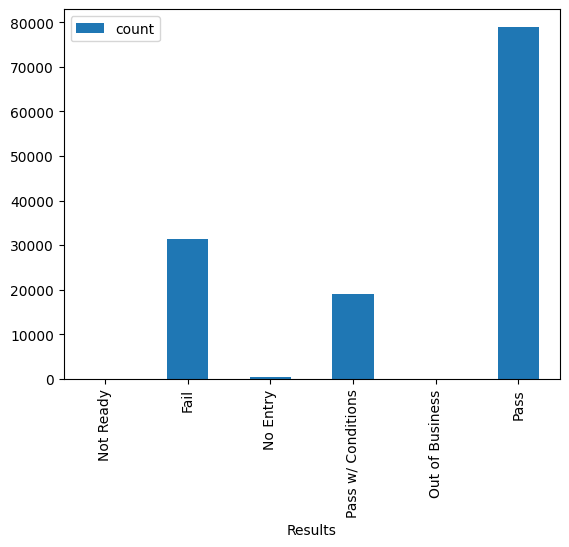

In [48]:
#convert Pyspark dataframe to Pandas dataframe for plotting
pdf = df2.toPandas()
pdf.plot(kind= 'bar', x='Results')

In [49]:
#Count results by result type 
df.groupby("Facility Type").count().sort("count").orderBy(["count"], ascending=[0]).show(20)

[Stage 202:>                                                        (0 + 8) / 9]

+--------------------+-----+
|       Facility Type|count|
+--------------------+-----+
|          RESTAURANT|89275|
|       GROCERY STORE|16688|
|              SCHOOL| 9507|
|              BAKERY| 1977|
|CHILDREN'S SERVIC...| 1880|
|DAYCARE (2 - 6 YE...| 1772|
|DAYCARE ABOVE AND...| 1555|
|      LONG TERM CARE|  987|
|            CATERING|  699|
|  DAYCARE COMBO 1586|  524|
|              LIQUOR|  437|
|        GOLDEN DINER|  386|
|            HOSPITAL|  320|
|           WHOLESALE|  304|
|MOBILE FOOD PREPARER|  296|
|MOBILE FOOD DISPE...|  266|
|              TAVERN|  177|
|DAYCARE (UNDER 2 ...|  151|
|             UNKNOWN|  110|
|       SPECIAL EVENT|  107|
+--------------------+-----+
only showing top 20 rows


#### Analyze Facility Risk 

In [50]:
#Risk by Facility type. 
df.crosstab('Facility Type', 'Risk').show()

[Stage 221:===================>                                     (3 + 6) / 9]

+--------------------+-------------+---------------+------------+
|  Facility Type_Risk|Risk 1 (High)|Risk 2 (Medium)|Risk 3 (Low)|
+--------------------+-------------+---------------+------------+
|       INTERNET CAFE|            0|              0|           1|
|      SHARED KITCHEN|           54|              5|           0|
|  GROCERY/RESTAURANT|           41|              0|           0|
|         BAKERY/DELI|            9|              0|           0|
|       BANQUET ROOMS|            7|              0|           0|
|  DRUG STORE/GROCERY|            0|              0|           2|
|            ROOFTOPS|            1|              7|           0|
|GROCERY STORE / G...|            0|              0|           4|
|               CANDY|            0|              0|           2|
|  WHOLESALE & RETAIL|            0|              0|           1|
|  RESTAURANT/GROCERY|            2|              0|           0|
|             BANQUET|           35|              3|           0|
|         

In [51]:
#Create a multi-dimensional cube with 2 dimensions
df.cube("Facility Type", "Risk").count().show()

[Stage 231:>                                                        (0 + 8) / 9]

+--------------------+---------------+-----+
|       Facility Type|           Risk|count|
+--------------------+---------------+-----+
|      RESTAURANT/BAR|Risk 2 (Medium)|    1|
|  DRUG/GROCERY STORE|   Risk 3 (Low)|    2|
|TAP ROOM/TAVERN/L...|           NULL|    1|
|          RESTAURANT|           NULL|89275|
|      PRIVATE SCHOOL|           NULL|   40|
|         GAS STATION|           NULL|   97|
|                POOL|  Risk 1 (High)|    3|
|     SENIOR DAY CARE|           NULL|    8|
|       HEALTH CENTER|Risk 2 (Medium)|    1|
|CHILDREN'S SERVIC...|           NULL| 1880|
|          DONUT SHOP|Risk 2 (Medium)|    7|
|CHILDREN'S SERVIC...|  Risk 1 (High)| 1874|
|          RESTAURANT|Risk 2 (Medium)|16133|
|DAYCARE ABOVE AND...|           NULL| 1555|
|         FOOD PANTRY|           NULL|    1|
|MOBILE FOOD PREPARER|Risk 2 (Medium)|  275|
|                NULL|Risk 2 (Medium)|25046|
|MOBILE FROZEN DES...|           NULL|   30|
|     ASSISTED LIVING|           NULL|   21|
|       MO

In [52]:
#Create a multi-dimensional cube with 3 dimensions
df.cube("Facility Type", "Risk", "Results").count().dropna().show()

[Stage 237:>                                                        (0 + 8) / 9]

+--------------------+---------------+------------------+-----+
|       Facility Type|           Risk|           Results|count|
+--------------------+---------------+------------------+-----+
|      LONG TERM CARE|  Risk 1 (High)|Pass w/ Conditions|  160|
|        LIVE POULTRY|Risk 2 (Medium)|              Fail|   19|
|        BANQUET HALL|  Risk 1 (High)|              Pass|   44|
|MOBILE FOOD PREPARER|Risk 2 (Medium)|              Fail|  131|
|        LIVE POULTRY|Risk 2 (Medium)|Pass w/ Conditions|    7|
|      SHARED KITCHEN|  Risk 1 (High)|              Fail|   12|
|       GROCERY STORE|Risk 2 (Medium)|              Fail| 1813|
|      LONG TERM CARE|  Risk 1 (High)|         Not Ready|    1|
|              SCHOOL|  Risk 1 (High)|              Fail| 1861|
|            CATERING|  Risk 1 (High)|              Fail|  141|
|          RESTAURANT|   Risk 3 (Low)|Pass w/ Conditions|   42|
|             SHELTER|  Risk 1 (High)|              Fail|   10|
|              BAKERY|Risk 2 (Medium)|  

In [53]:
#Pivot Data - convert categorical value from row into Columns and count
df3 = df.groupBy("Facility Type").pivot("Risk").count()
df3.dropna().show()

[Stage 256:>                                                        (0 + 8) / 9]

+--------------------+-------------+---------------+------------+
|       Facility Type|Risk 1 (High)|Risk 2 (Medium)|Risk 3 (Low)|
+--------------------+-------------+---------------+------------+
|              BAKERY|          827|           1142|           8|
|MOBILE FOOD DISPE...|            8|             30|         228|
|              LIQUOR|            6|             12|         419|
|           WHOLESALE|           51|             99|         154|
|       SPECIAL EVENT|           46|             55|           6|
|              CHURCH|            8|             16|           2|
|SHARED KITCHEN US...|           10|              1|           2|
|          COMMISSARY|           11|              5|           1|
|        BANQUET HALL|           73|              3|           2|
|         GAS STATION|            5|             13|          79|
|             UNKNOWN|           58|             21|          31|
|          RESTAURANT|        72679|          16133|         463|
|       GR

<Axes: xlabel='Facility Type'>

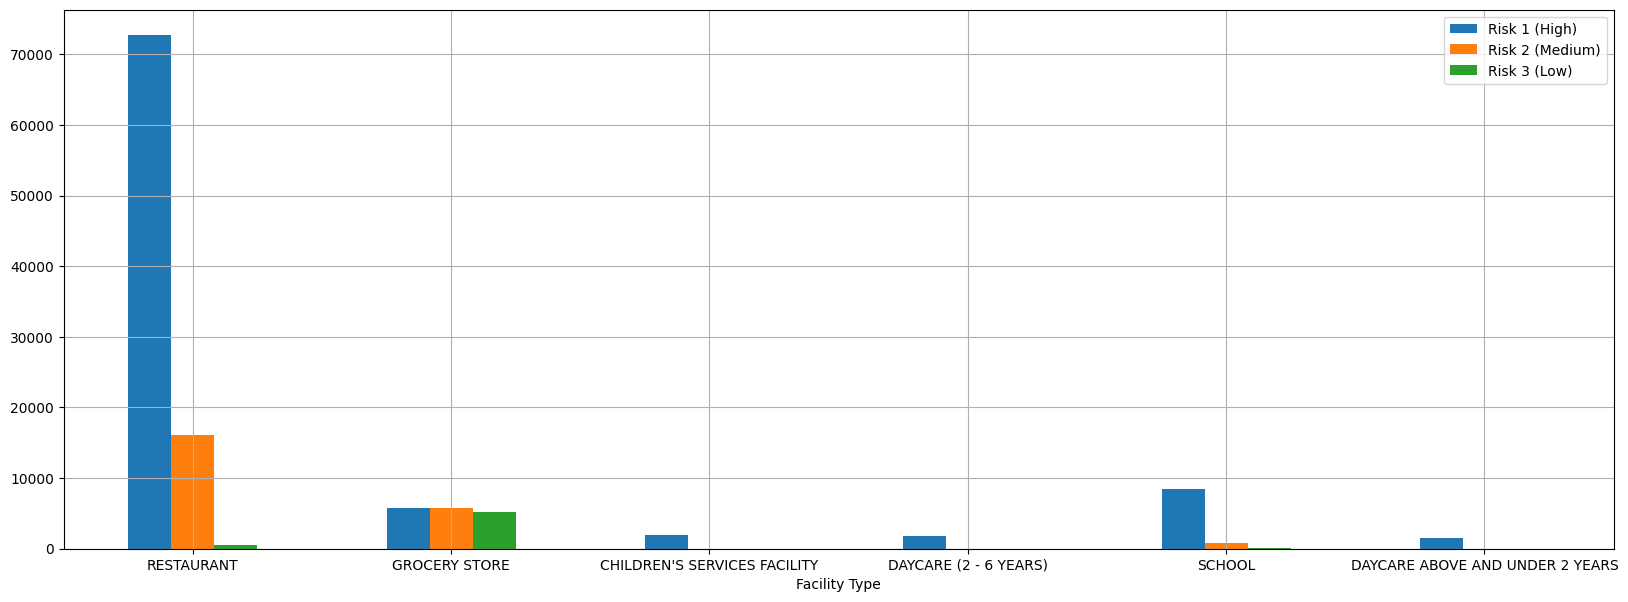

In [54]:
#plot some of the Facility Types risk profile
pdf = df3.toPandas()
pdf[pdf["Risk 1 (High)"] > 1000].plot(figsize=(20,7), kind='bar', x="Facility Type", grid=True, rot=0)

In [55]:
#Count facility type by highest number of High risks using expression 
df3.agg({"Risk 1 (High)": "max"}).collect()[0][0]

72679

In [56]:
#Maximum number of High risks using max function
from pyspark.sql.functions import max
df3.agg(max(df3["Risk 1 (High)"])).head()[0]

72679

#### Analyze Inspections and Failures

In [57]:
#which DBA had the most inspections
df.groupby("DBA Name").count().orderBy(["count"], ascending=[0]).show(10)

[Stage 306:======>                                                  (1 + 8) / 9]

+--------------------+-----+
|            DBA Name|count|
+--------------------+-----+
|              SUBWAY| 1969|
|       DUNKIN DONUTS| 1010|
|          MCDONALD'S|  410|
|            7-ELEVEN|  318|
|           MCDONALDS|  249|
|CHIPOTLE MEXICAN ...|  235|
|POTBELLY SANDWICH...|  230|
|  CORNER BAKERY CAFE|  205|
|POTBELLY SANDWICH...|  192|
|DUNKIN DONUTS/BAS...|  162|
+--------------------+-----+
only showing top 10 rows


In [58]:
#maximum number of inspections
df.groupby("DBA Name").count().agg(F.max("count")).show()

[Stage 310:==============>                                          (2 + 6) / 8]

+----------+
|max(count)|
+----------+
|      1969|
+----------+



In [59]:
#which restaurants failed the most inspections - using Filter
df.filter(df.Results == "Fail").groupby("DBA Name").count().orderBy(["count"], ascending=[0]).show(10)

[Stage 320:==============>                                          (2 + 6) / 8]

+--------------------+-----+
|            DBA Name|count|
+--------------------+-----+
|              SUBWAY|  289|
|       DUNKIN DONUTS|  176|
|          MCDONALD'S|   95|
|            7-ELEVEN|   57|
|           MCDONALDS|   53|
|POTBELLY SANDWICH...|   47|
|HAROLD'S CHICKEN ...|   47|
|CHIPOTLE MEXICAN ...|   39|
|               CITGO|   38|
|    LAS ISLAS MARIAS|   36|
+--------------------+-----+
only showing top 10 rows


In [60]:
#which restaurants failed the most inspections - using Pivots
df_fails = df.groupBy("DBA Name").pivot("Results").count().orderBy(["Fail"], ascending=[0])

df_fails.show(10)

[Stage 341:=========================>                               (4 + 5) / 9]

+--------------------+----+--------+---------+---------------+----+------------------+
|            DBA Name|Fail|No Entry|Not Ready|Out of Business|Pass|Pass w/ Conditions|
+--------------------+----+--------+---------+---------------+----+------------------+
|              SUBWAY| 289|    NULL|     NULL|           NULL|1253|               427|
|       DUNKIN DONUTS| 176|    NULL|     NULL|              1| 622|               211|
|          MCDONALD'S|  95|    NULL|     NULL|           NULL| 255|                60|
|            7-ELEVEN|  57|    NULL|     NULL|           NULL| 193|                68|
|           MCDONALDS|  53|    NULL|        1|           NULL| 146|                49|
|POTBELLY SANDWICH...|  47|    NULL|     NULL|           NULL| 162|                21|
|HAROLD'S CHICKEN ...|  47|    NULL|     NULL|           NULL|  76|                22|
|CHIPOTLE MEXICAN ...|  39|    NULL|     NULL|           NULL| 154|                42|
|               CITGO|  38|    NULL|     NU

In [61]:
#examine failure rates
df_fails  = df_fails.withColumn("Fail Rate", df_fails.Fail*100/(df_fails.Fail + df_fails.Pass + df_fails["Pass w/ Conditions"]))
df_fails.orderBy(["Fail Rate"], ascending=[0]).drop("No Entry", "Not Ready", "Out Of Business").show(20, truncate = False)

[Stage 349:==============>                                          (2 + 6) / 8]

+-----------------------------------------------+----+----+------------------+-----------------+
|DBA Name                                       |Fail|Pass|Pass w/ Conditions|Fail Rate        |
+-----------------------------------------------+----+----+------------------+-----------------+
|CHEESIE'S PUB & GRUB                           |8   |1   |1                 |80.0             |
|ELBO FOOD MART, INC.,                          |6   |1   |1                 |75.0             |
|BABA PITA PALACE                               |6   |1   |1                 |75.0             |
|COMMONWEALTH DAYCARE CENTER                    |6   |1   |1                 |75.0             |
|TUK OF CHICAGO                                 |6   |1   |1                 |75.0             |
|EL SALVADOR RESTAURANT                         |6   |1   |1                 |75.0             |
|METHODIST HOSPITAL OF CHICAGO                  |6   |1   |1                 |75.0             |
|SHIRLEY SOUL FOOD AND CATERIN

## DateTime Functions

In [62]:
from pyspark.sql.functions import month, year
df = df.withColumn('Year', year(df['Inspection Date']))
df = df.withColumn('Month', month(df['Inspection Date']))
df.show(2)

[Stage 359:==============>                                          (2 + 6) / 8]

+-------------+--------------------+---------+-------------+-------------+--------------------+-------+-----+-----+-------------------+--------------------+-------+--------------------+------------------+------------------+-------+----+-----+
|Inspection ID|            DBA Name|License #|Facility Type|         Risk|             Address|   City|State|  Zip|    Inspection Date|     Inspection Type|Results|          Violations|          Latitude|         Longitude|  Cityd|Year|Month|
+-------------+--------------------+---------+-------------+-------------+--------------------+-------+-----+-----+-------------------+--------------------+-------+--------------------+------------------+------------------+-------+----+-----+
|      2240246|NEW HONG KONG BUF...|  2510903|   RESTAURANT|Risk 1 (High)|6249 N MCCORMICK RD |CHICAGO|   IL|60659|2018-11-15 00:00:00|Short Form Complaint|   Fail|10. ADEQUATE HAND...|41.995440602185084|-87.71291737890452|CHICAGO|2018|   11|
|      2233162|MS. B'S KITCH

In [63]:
#inspections for November 2018
inspections = df.filter(df.Year == '2018').filter(df.Month == "11")

#convert to pandas for later use
inspections_pdf = inspections.toPandas()
inspections_pdf.head(2)

,Inspection ID,DBA Name,License #,Facility Type,Risk,Address,City,State,Zip,Inspection Date,Inspection Type,Results,Violations,Latitude,Longitude,Cityd,Year,Month
0,2240246,"NEW HONG KONG BUFFET, INC",2510903,RESTAURANT,Risk 1 (High),6249 N MCCORMICK RD,CHICAGO,IL,60659,2018-11-15,Short Form Complaint,Fail,10. ADEQUATE HANDWASHING SINKS PROPERLY SUPPLI...,41.995441,-87.712917,CHICAGO,2018,11
1,2233162,MS. B'S KITCHEN & CATERING LLC,2631695,RESTAURANT,Risk 1 (High),4203 W CERMAK RD,CHICAGO,IL,60623,2018-11-14,License Re-Inspection,Fail,"3. MANAGEMENT, FOOD EMPLOYEE AND CONDITIONAL E...",41.851366,-87.729766,CHICAGO,2018,11


In [64]:
#Group by Year and Month and sort in asending order
df4 = df.groupBy('Year', 'Month').count().orderBy(["Year", "Month"], ascending=[0, 0])
df4.show()

[Stage 367:>                                                        (0 + 8) / 9]

+----+-----+-----+
|Year|Month|count|
+----+-----+-----+
|2018|   11|  253|
|2018|   10|  815|
|2018|    9|  872|
|2018|    8| 1100|
|2018|    7|  868|
|2018|    6| 1147|
|2018|    5| 1211|
|2018|    4| 1315|
|2018|    3| 1185|
|2018|    2| 1052|
|2018|    1| 1260|
|2017|   12|  885|
|2017|   11| 1129|
|2017|   10| 1337|
|2017|    9| 1298|
|2017|    8| 1354|
|2017|    7| 1106|
|2017|    6| 1659|
|2017|    5| 1559|
|2017|    4| 1258|
+----+-----+-----+
only showing top 20 rows


<Axes: >

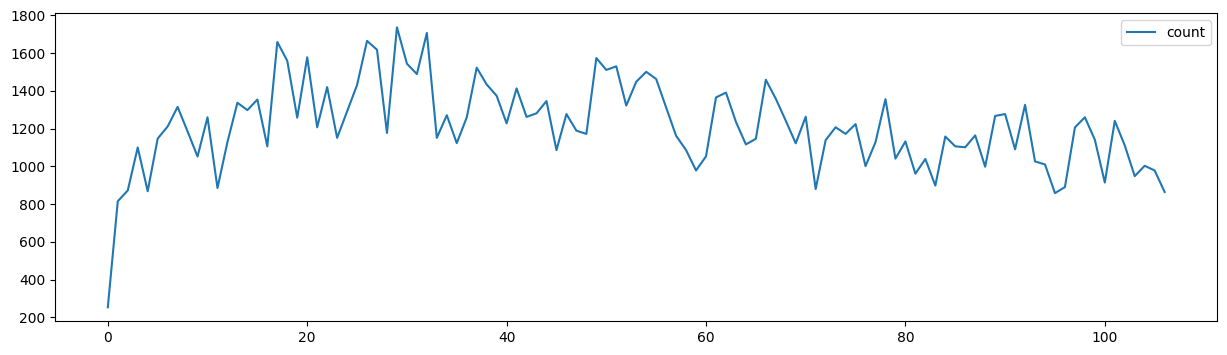

In [65]:
#Plot Inspections over time
pdf = df4.toPandas()
pdf.plot(y="count", figsize=(15,4), style="-")

In [66]:
#year over year analysis
pdf = pdf.pivot(index='Month', columns='Year', values='count')
pdf

Year,2010,2011,2012,2013,2014,2015,2016,2017,2018
Month,,,,,,,,,
1,864.0,1010.0,1039.0,1263.0,1086.0,1277.0,1271.0,1420.0,1260.0
2,978.0,1026.0,961.0,1122.0,1162.0,1086.0,1151.0,1207.0,1052.0
3,1003.0,1326.0,1132.0,1242.0,1312.0,1346.0,1707.0,1578.0,1185.0
4,948.0,1090.0,1041.0,1358.0,1463.0,1281.0,1489.0,1258.0,1315.0
5,1111.0,1277.0,1356.0,1459.0,1501.0,1262.0,1544.0,1559.0,1211.0
6,1241.0,1267.0,1128.0,1146.0,1448.0,1413.0,1737.0,1659.0,1147.0
7,914.0,998.0,1001.0,1116.0,1322.0,1228.0,1177.0,1106.0,868.0
8,1141.0,1164.0,1224.0,1236.0,1530.0,1374.0,1618.0,1354.0,1100.0
9,1260.0,1101.0,1172.0,1391.0,1511.0,1434.0,1665.0,1298.0,872.0


<Axes: xlabel='Month'>

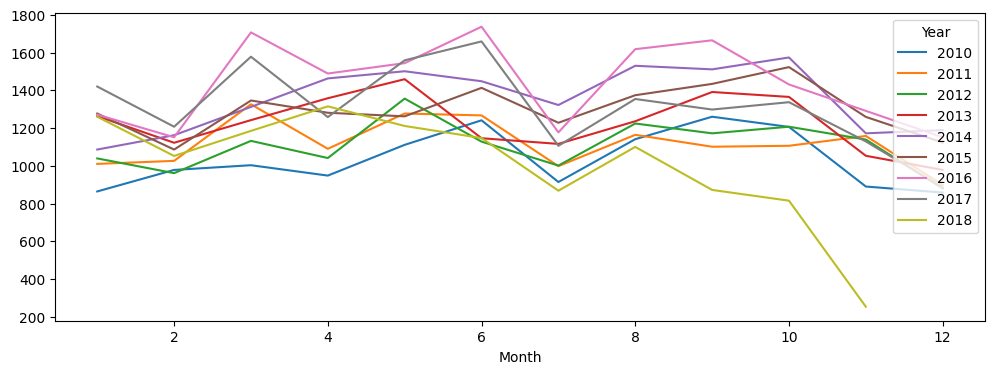

In [67]:
pdf.plot(figsize=(12,4))

In [68]:
#min,max and avg inspections in each month
df4.groupBy('Month').agg(F.min('count'),F.max('count'),F.avg('count')).show()

[Stage 384:==========================================>              (6 + 2) / 8]

+-----+----------+----------+------------------+
|Month|min(count)|max(count)|        avg(count)|
+-----+----------+----------+------------------+
|   12|       858|      1189|            995.25|
|    1|       864|      1420|1165.5555555555557|
|    6|      1128|      1737|            1354.0|
|    3|      1003|      1707|1314.5555555555557|
|    5|      1111|      1559|1364.4444444444443|
|    9|       872|      1665|1300.4444444444443|
|    4|       948|      1489|1249.2222222222222|
|    8|      1100|      1618|1304.5555555555557|
|    7|       868|      1322| 1081.111111111111|
|   10|       815|      1574| 1284.888888888889|
|   11|       253|      1291|1038.2222222222222|
|    2|       961|      1207|1082.7777777777778|
+-----+----------+----------+------------------+



### String Operations

In [69]:
df.select('Violations').show(5, truncate=False)

[Stage 394:==============>                                          (2 + 6) / 8]

+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [70]:
#how many inspections mention Rodents, but did not fail inspection
df.filter("Violations like '%RODENT%'").filter("Results <> 'Fail'").count()

4086

In [71]:
#split/pivot Violations column into multiple columns based on pipe separator
split_col = F.split(df['Violations'], '\\|')

df.withColumn('V1', split_col.getItem(0))\
.withColumn('V2', split_col.getItem(1))\
.withColumn('V3', split_col.getItem(3))\
.select ('Inspection ID','V1', 'V2', 'V3').show(10)

[Stage 403:=====================>                                   (3 + 5) / 8]

+-------------+--------------------+--------------------+--------------------+
|Inspection ID|                  V1|                  V2|                  V3|
+-------------+--------------------+--------------------+--------------------+
|      2240246|10. ADEQUATE HAND...| 10. ADEQUATE HAN...| 23. PROPER DATE ...|
|      2233162|3. MANAGEMENT, FO...| 5. PROCEDURES FO...| 39. CONTAMINATIO...|
|      2232970|3. MANAGEMENT, FO...| 5. PROCEDURES FO...| 25. CONSUMER ADV...|
|      2232799|3. MANAGEMENT, FO...| 5. PROCEDURES FO...| 31. WATER & ICE ...|
|      2232662|2. CITY OF CHICAG...| 3. MANAGEMENT, F...| 37. FOOD PROPERL...|
|      2232559|3. MANAGEMENT, FO...| 5. PROCEDURES FO...| 25. CONSUMER ADV...|
|      2232520|1. PERSON IN CHAR...| 3. MANAGEMENT, F...| 23. PROPER DATE ...|
|      2232494|3. MANAGEMENT, FO...| 5. PROCEDURES FO...| 33. PROPER COOLI...|
|      2232481|3. MANAGEMENT, FO...| 5. PROCEDURES FO...| 38. INSECTS, ROD...|
|      2232463|1. PERSON IN CHAR...| 2. CITY OF CHIC

In [72]:
#max violations
from pyspark.sql.functions import max
df = df.withColumn('VIOLATIONS_COUNT', F.size(F.split(F.col('VIOLATIONS'), '\\|')))
maxv = df.agg(max(df.VIOLATIONS_COUNT)).head()[0]
maxv

34

In [73]:
#general method to create new columns for all violations
#for i in range(maxv):
#    df = df.withColumn('V' + str(i), split_col.getItem(i))

from pyspark.sql.functions import get

# General method to create new columns for all violations
for i in range(maxv):
    df = df.withColumn('V' + str(i), get(split_col, i))

In [74]:
df.show(5, truncate=False)

[Stage 412:=======>                                                 (1 + 7) / 8]

+-------------+------------------------------+---------+-------------+-------------+--------------------------+-------+-----+-----+-------------------+---------------------+-------+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

### Spark SQL

In [75]:
#Register the DataFrame as a SQL temporary view
df.createOrReplaceTempView("inspections")

# Register the DataFrame as a global temporary view
# df.createGlobalTempView("inspections")

In [76]:
sqlDF = spark.sql("SELECT * FROM inspections")
sqlDF.show(10)

[Stage 415:=======>                                                 (1 + 7) / 8]

+-------------+--------------------+---------+-------------+---------------+--------------------+-------+-----+-----+-------------------+--------------------+-------+--------------------+------------------+------------------+-------+----+-----+----------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+----+----+----+----+----+----+----+----+----+----+----+----+----+----+
|Inspection ID|            DBA Name|License #|Facility Type|           Risk|             Address|   City|State|  Zip|    Inspection Date|     Inspection Type|Results|          Violations|          Latitude|         Longitude|  Cityd|Year|Month|VIOL

In [77]:
#select one or more columns
sqlDF = spark.sql("SELECT `DBA Name` FROM inspections")
sqlDF.show(10)

[Stage 418:=======>                                                 (1 + 7) / 8]

+--------------------+
|            DBA Name|
+--------------------+
|NEW HONG KONG BUF...|
|MS. B'S KITCHEN &...|
|         KABAB GRILL|
|MS. B'S KITCHEN &...|
|CREMERIA SANTA MA...|
|        HALAL BURGER|
|    CERMAK FOOD MART|
|     TEA LEAF GARDEN|
|   NUEVO LEON BAKERY|
|      RIGO'S GROCERY|
+--------------------+
only showing top 10 rows


## Data Augmentation

Lets try to get additional information about Chicago resturants from the City of Chicago data portal. We can use the license id column to join the two data sets.

https://data.cityofchicago.org/Community-Economic-Development/Business-Licenses/r5kz-chrr

In [78]:
# Download CSV from GCS
# Workaround only; not recommended for very large datasets

from google.cloud import storage

client = storage.Client()

bucket = client.bucket("adsp-31011-ip07-f26-bucket")
blob = bucket.blob("Business_Licenses.csv")

blob.download_to_filename("/tmp/Business_Licenses.csv")

In [79]:
df1 = spark.read.csv(
    "file:///tmp/Business_Licenses.csv",
    header=True,
    inferSchema=True
)

In [80]:
df1.printSchema()

root
 |-- ID: string (nullable = true)
 |-- LICENSE ID: integer (nullable = true)
 |-- ACCOUNT NUMBER: integer (nullable = true)
 |-- SITE NUMBER: integer (nullable = true)
 |-- LEGAL NAME: string (nullable = true)
 |-- DOING BUSINESS AS NAME: string (nullable = true)
 |-- ADDRESS: string (nullable = true)
 |-- CITY: string (nullable = true)
 |-- STATE: string (nullable = true)
 |-- ZIP CODE: string (nullable = true)
 |-- WARD: string (nullable = true)
 |-- PRECINCT: string (nullable = true)
 |-- WARD PRECINCT: string (nullable = true)
 |-- POLICE DISTRICT: string (nullable = true)
 |-- LICENSE CODE: string (nullable = true)
 |-- LICENSE DESCRIPTION: string (nullable = true)
 |-- BUSINESS ACTIVITY ID: string (nullable = true)
 |-- BUSINESS ACTIVITY: string (nullable = true)
 |-- LICENSE NUMBER: string (nullable = true)
 |-- APPLICATION TYPE: string (nullable = true)
 |-- APPLICATION CREATED DATE: string (nullable = true)
 |-- APPLICATION REQUIREMENTS COMPLETE: string (nullable = true)


In [81]:
#only select columns of interest 
df1 = df1.select("LICENSE ID","LEGAL NAME", "DOING BUSINESS AS NAME", "BUSINESS ACTIVITY", "LICENSE DESCRIPTION", "LICENSE STATUS", "CONDITIONAL APPROVAL")

In [82]:
df1.count()

957985

In [83]:
df.count()

129820

In [84]:
#this creates an inner join between the two datasets
dfc = df.join(df1, df["License #"]== df1["LICENSE ID"])

In [85]:
#we have lost some records because of the inner join because of no matches
dfc.count()

92065

In [86]:
#A left join preserves all rows from our original dataset
dfc = df.join(df1, df["License #"]== df1["LICENSE ID"], "left_outer")

In [87]:
#check total record count
dfc.count()

129820

In [88]:
#lots of duplicate columns
dfc.printSchema()

root
 |-- Inspection ID: integer (nullable = true)
 |-- DBA Name: string (nullable = true)
 |-- License #: integer (nullable = true)
 |-- Facility Type: string (nullable = false)
 |-- Risk: string (nullable = true)
 |-- Address: string (nullable = true)
 |-- City: string (nullable = true)
 |-- State: string (nullable = true)
 |-- Zip: integer (nullable = true)
 |-- Inspection Date: timestamp (nullable = true)
 |-- Inspection Type: string (nullable = true)
 |-- Results: string (nullable = true)
 |-- Violations: string (nullable = true)
 |-- Latitude: double (nullable = true)
 |-- Longitude: double (nullable = true)
 |-- Cityd: string (nullable = true)
 |-- Year: integer (nullable = true)
 |-- Month: integer (nullable = true)
 |-- VIOLATIONS_COUNT: integer (nullable = true)
 |-- V0: string (nullable = true)
 |-- V1: string (nullable = true)
 |-- V2: string (nullable = true)
 |-- V3: string (nullable = true)
 |-- V4: string (nullable = true)
 |-- V5: string (nullable = true)
 |-- V6: stri

In [89]:
#Find out restaurants where the DBA name is different from the Legal Name
dfc.where(dfc["DBA Name"] != dfc["Legal Name"]).select("DBA Name", "Legal Name").show(truncate=False)

[Stage 449:============>                                            (2 + 7) / 9]

+-------------------------------------+-------------------------------------+
|DBA Name                             |Legal Name                           |
+-------------------------------------+-------------------------------------+
|ROYCE CHICAGO                        |MR HIRMAN LLC                        |
|A & C DISTRIBUTORS                   |CICHON CORPORATION                   |
|A & C DISTRIBUTORS                   |CICHON CORPORATION                   |
|THE SPICE ROOM                       |HARISH AND SURESH, INC.              |
|THE SPICE ROOM                       |HARISH AND SURESH, INC.              |
|MI FIESTA RESTAURANT & CATERING, INC |MI FIESTA RESTAURANT & CATERING, INC.|
|MI FIESTA RESTAURANT & CATERING, INC |MI FIESTA RESTAURANT & CATERING, INC.|
|MI FIESTA RESTAURANT & CATERING, INC |MI FIESTA RESTAURANT & CATERING, INC.|
|ACE HOTEL CHICAGO                    |ACE GROUP CHICAGO LLC                |
|ACE HOTEL CHICAGO                    |ACE GROUP CHICAGO LLC    

In [90]:
#Count inspection failures by type of license
#assuming one license type per establishment
dfc.filter(dfc["Results"] == "Fail").groupby("LICENSE DESCRIPTION").count().orderBy(["count"], ascending=[0]).show(truncate=False)

[Stage 456:============================>                            (4 + 4) / 8]

+---------------------------------------------+-----+
|LICENSE DESCRIPTION                          |count|
+---------------------------------------------+-----+
|Retail Food Establishment                    |20087|
|NULL                                         |8379 |
|Children's Services Facility License         |778  |
|Consumption on Premises - Incidental Activity|402  |
|Mobile Food License                          |238  |
|Day Care Center Under 2 and 2 - 6 Years      |198  |
|Limited Business License                     |193  |
|Regulated Business License                   |189  |
|Package Goods                                |139  |
|Day Care Center 2 - 6 Years                  |133  |
|Tavern                                       |128  |
|Wholesale Food Establishment                 |118  |
|Mobile Food Dispenser                        |68   |
|Day Care Center Under 2 Years                |61   |
|Long-Term Care Facility                      |41   |
|Caterer's Liquor License   